In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [3]:
train = pd.read_csv("../Data/Cleaned/train_ready.csv")
test = pd.read_csv("../Data/Cleaned/test_ready.csv")

target = "Waste_Amount_kg"
X_train, y_train = train.drop(columns=[target]), train[target]
X_test, y_test = test.drop(columns=[target]), test[target]

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Target mean (train): {y_train.mean():.2f} kg, std: {y_train.std():.2f}")

X_train: (800, 27) | X_test: (200, 27)
Target mean (train): 9.60 kg, std: 6.68


In [ ]:
# Same folds for every model, fixed seed
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv,
                         scoring=["r2", "neg_root_mean_squared_error", "neg_mean_absolute_error"])
    rows.append({
        "Model": name,
        "CV R2 mean": res["test_r2"].mean(),
        "CV R2 std": res["test_r2"].std(),
        "CV RMSE": -res["test_neg_root_mean_squared_error"].mean(),
        "CV MAE": -res["test_neg_mean_absolute_error"].mean(),
    })

cv_table = pd.DataFrame(rows).set_index("Model").round(3)
print("--- 5-FOLD CROSS-VALIDATION ON TRAIN ---")
display(cv_table)

--- 5-FOLD CROSS-VALIDATION ON TRAIN ---


,CV R2 mean,CV R2 std,CV RMSE,CV MAE
Model,,,,
Baseline (mean),-0.003,0.004,6.670,5.408
Linear Regression,0.542,0.026,4.505,3.521
Ridge,0.542,0.026,4.505,3.521
Random Forest,0.530,0.014,4.563,3.561
Gradient Boosting,0.556,0.022,4.433,3.481


In [ ]:
ridge_search = GridSearchCV(
    Ridge(),
    param_grid={"alpha": [0.01, 0.1, 1, 10, 100]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
ridge_search.fit(X_train, y_train)
print(f"Ridge best params: {ridge_search.best_params_}")
print(f"Ridge best CV RMSE: {-ridge_search.best_score_:.3f}")

Ridge best params: {'alpha': 1}
Ridge best CV RMSE: 4.505


In [ ]:
rf_search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid={
        "n_estimators": [100, 300],
        "max_depth": [5, 10, None],
        "min_samples_leaf": [1, 5, 10],
    },
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
rf_search.fit(X_train, y_train)
print(f"Random Forest best params: {rf_search.best_params_}")
print(f"Random Forest best CV RMSE: {-rf_search.best_score_:.3f}")

Random Forest best params: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 300}
Random Forest best CV RMSE: 4.501


In [ ]:
gb_search = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid={
        "n_estimators": [100, 200],
        "learning_rate": [0.03, 0.1],
        "max_depth": [2, 3],
    },
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
gb_search.fit(X_train, y_train)
print(f"Gradient Boosting best params: {gb_search.best_params_}")
print(f"Gradient Boosting best CV RMSE: {-gb_search.best_score_:.3f}")

Gradient Boosting best params: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}
Gradient Boosting best CV RMSE: 4.360


In [ ]:
final_models = {
    "Baseline (mean)": DummyRegressor(strategy="mean").fit(X_train, y_train),
    "Linear Regression": LinearRegression().fit(X_train, y_train),
    "Ridge": ridge_search.best_estimator_,
    "Random Forest": rf_search.best_estimator_,
    "Gradient Boosting": gb_search.best_estimator_,
}

results = []
predictions = {}
for name, model in final_models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

results_table = pd.DataFrame(results).set_index("Model").sort_values("RMSE").round(3)
print("--- TEST SET RESULTS (sorted by RMSE, lower is better) ---")
display(results_table)

--- TEST SET RESULTS (sorted by RMSE, lower is better) ---


,MAE,RMSE,R2
Model,,,
Gradient Boosting,3.157,4.110,0.628
Linear Regression,3.329,4.243,0.604
Ridge,3.330,4.244,0.604
Random Forest,3.265,4.289,0.595
Baseline (mean),5.573,6.762,-0.006


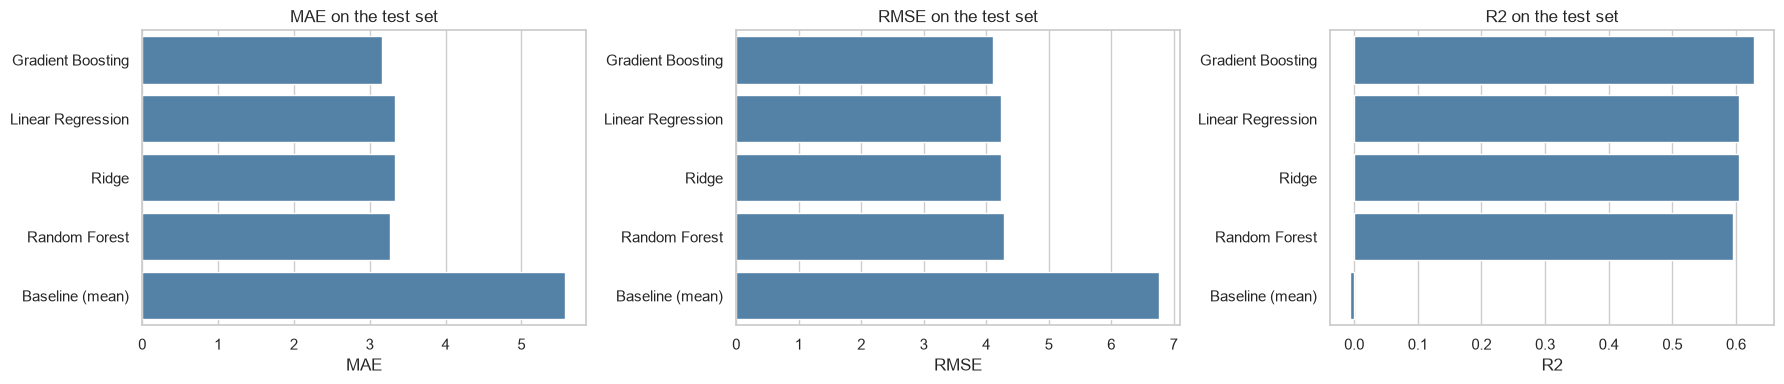

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    sns.barplot(x=results_table[metric], y=results_table.index, color="steelblue", ax=ax)
    ax.set_title(f"{metric} on the test set")
    ax.set_xlabel(metric)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Best model: Gradient Boosting


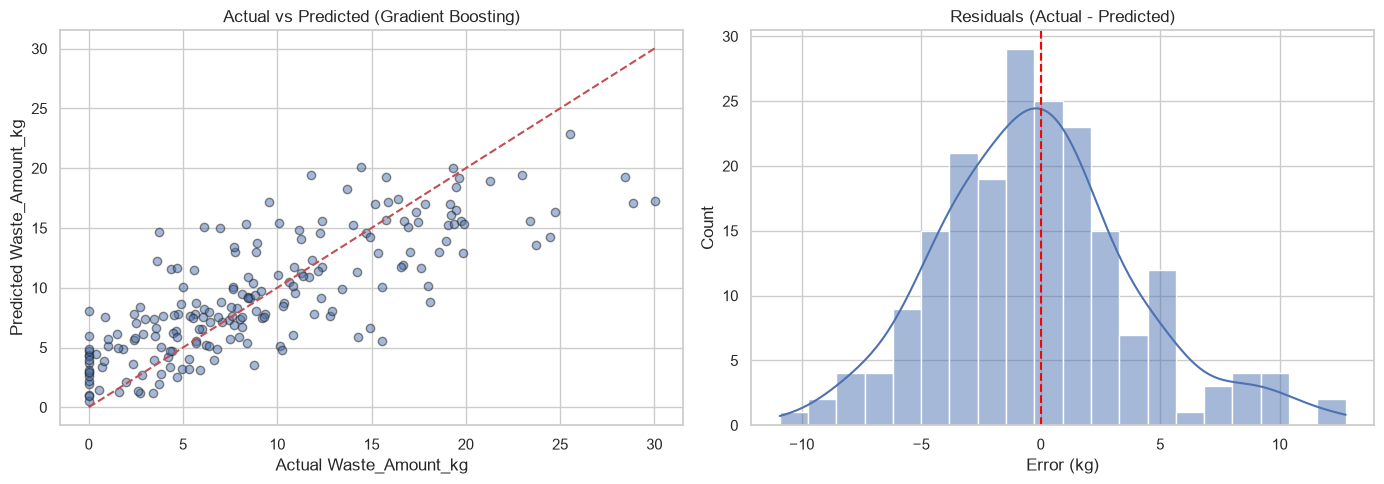

In [ ]:
best_name = results_table.drop(index="Baseline (mean)")["RMSE"].idxmin()
best_model = final_models[best_name]
best_pred = predictions[best_name]
print(f"Best model: {best_name}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, best_pred, alpha=0.5, edgecolor="k")
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
axes[0].plot(lims, lims, "r--")
axes[0].set_title(f"Actual vs Predicted ({best_name})")
axes[0].set_xlabel("Actual Waste_Amount_kg")
axes[0].set_ylabel("Predicted Waste_Amount_kg")

residuals = y_test - best_pred
sns.histplot(residuals, kde=True, bins=20, ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Residuals (Actual - Predicted)")
axes[1].set_xlabel("Error (kg)")
plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
Path("../Models").mkdir(exist_ok=True)

for name, model in final_models.items():
    file_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    joblib.dump(model, f"../Models/{file_name}.joblib")

results_table.to_csv("../Models/model_results.csv")
print("--- MODELS SAVED IN Models/ ---")
print(sorted(f.name for f in Path("../Models").glob("*")))

--- MODELS SAVED IN Models/ ---
['baseline_mean.joblib', 'gradient_boosting.joblib', 'linear_regression.joblib', 'model_results.csv', 'random_forest.joblib', 'ridge.joblib']


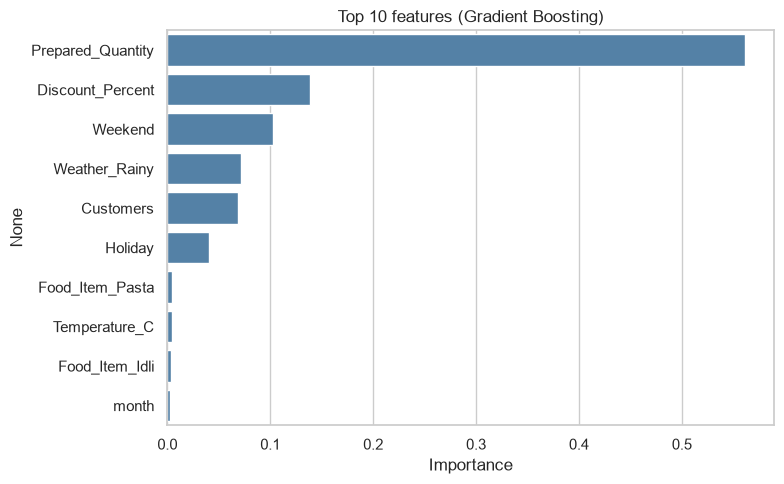

In [ ]:
# Which features does the best model rely on?
if hasattr(best_model, "feature_importances_"):
    importance = pd.Series(best_model.feature_importances_, index=X_train.columns)
else:
    importance = pd.Series(np.abs(best_model.coef_), index=X_train.columns)

top = importance.sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=top.values, y=top.index, color="steelblue")
plt.title(f"Top 10 features ({best_name})")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [ ]:
import joblib

for name, model in models.items():
    file_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "") + ".joblib"
    joblib.dump(model, f"../Models/{file_name}")

# استبدل results_df بالاسم الصحيح لجدول النتائج عندك (مثلاً results_table)
results_table.to_csv("model_results.csv", index=False)
print("--- MODELS SAVED ---")

--- MODELS SAVED ---


In [ ]:
from sklearn.utils.validation import check_is_fitted

for name, model in final_models.items():
    check_is_fitted(model)
    print(name, "= fitted")

Baseline (mean) = fitted
Linear Regression = fitted
Ridge = fitted
Random Forest = fitted
Gradient Boosting = fitted


In [5]:
# تحميل النموذج وحفظ تنبؤاته الجديدة للتأكد
check = joblib.load("../Models/random_forest.joblib")
test_preds = check.predict(X_test)
assert len(test_preds) == len(X_test)
print("Reload check passed: the saved Random Forest model is working correctly.")

Reload check passed: the saved Random Forest model is working correctly.


In [ ]:
from sklearn.utils.validation import check_is_fitted

for name, model in final_models.items():
    try:
        check_is_fitted(model)
        print(name, "مدرّب")
    except Exception:
        print(name, "غير مدرّب")

Baseline (mean) مدرّب
Linear Regression مدرّب
Ridge مدرّب
Random Forest مدرّب
Gradient Boosting مدرّب


In [ ]:
import joblib
from sklearn.utils.validation import check_is_fitted
from pathlib import Path

for file in Path("../Models").glob("*.joblib"):
    model = joblib.load(file)
    try:
        check_is_fitted(model)
        print(file.name, "مدرّب")
    except Exception:
        print(file.name, "غير مدرّب")

baseline_mean.joblib مدرّب
gradient_boosting.joblib مدرّب
linear_regression.joblib مدرّب
random_forest.joblib مدرّب
ridge.joblib مدرّب


In [ ]:
from pathlib import Path
import joblib

# تحديد مجلد المشروع الرئيسي تلقائياً
current = Path.cwd()
project_root = next(
    (p for p in [current, *current.parents]
     if (p / "Data").is_dir() and (p / "Notebooks").is_dir()),
    None
)

if project_root is None:
    raise FileNotFoundError("لم يتم العثور على مجلد المشروع")

# حفظ النماذج في Models الرئيسي
model_dir = project_root / "Models"
model_dir.mkdir(parents=True, exist_ok=True)

for name, model in final_models.items():
    file_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "")
    joblib.dump(model, model_dir / f"{file_name}.joblib")

print(f"تم حفظ النماذج بنجاح في: {model_dir}")

تم حفظ النماذج بنجاح في: c:\Users\Admin\Desktop\food\Models
